# Classification automatique de commentaires citoyens sur les services publics

### Test technique NLP — TAISS 2026 / Afriklang

**Objectif :** développer un pipeline de traitement automatique du langage naturel permettant de classifier des commentaires citoyens en trois catégories :

- Satisfaction
- Insatisfaction
- Suggestion

**Auteur :** DEFALEOUNA Tchassama Dessoklema(maximedefa@gmail.com) 

**Langage :** Python  
**Dataset :** `dataset_nlp_test_tal.csv`

## 1. Contexte

Les services publics reçoivent de nombreux commentaires de la part des citoyens.

L'objectif de ce projet est d'explorer et de construire une approche automatique permettant de classifier ces commentaires selon trois catégories :

1. **Satisfaction** : retours positifs concernant les services publics.
2. **Insatisfaction** : plaintes ou expériences négatives.
3. **Suggestion** : propositions visant à améliorer les services.

Le jeu de données fourni contient principalement des commentaires en français, avec également quelques insertions de termes ou expressions en éwé/mina.

Le projet suit un pipeline NLP complet, allant de l'exploration des données jusqu'à l'évaluation et l'interprétation des modèles.

## 2. Objectifs

Les objectifs de cette étude sont les suivants :

- comprendre la structure et la qualité du jeu de données ;
- analyser la distribution des catégories ;
- étudier les caractéristiques textuelles des commentaires ;
- mettre en place un prétraitement adapté au contexte multilingue ;
- transformer les textes en représentations numériques ;
- entraîner plusieurs modèles de classification ;
- comparer leurs performances ;
- analyser les erreurs de classification ;
- identifier les limites de l'approche ;
- proposer des pistes d'amélioration.

## **Importation des bibliothèques**

In [74]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Configuration d'affichage
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

## 3. Configuration

Cette section définit les paramètres généraux utilisés dans le notebook afin de favoriser la reproductibilité des résultats.

In [75]:
RANDOM_STATE = 42

DATA_PATH = Path("dataset_nlp_test_tal.csv")

TARGET_COLUMN = "categorie"
TEXT_COLUMN = "texte"
ID_COLUMN = "id"

## 4. Chargement des données

Le jeu de données fourni par Togo AI Lab est chargé à partir du fichier CSV `dataset_nlp_test_tal.csv`.

In [76]:
df = pd.read_csv(DATA_PATH)

print("Dataset chargé avec succès.")
print(f"Nombre de lignes : {df.shape[0]}")
print(f"Nombre de colonnes : {df.shape[1]}")

Dataset chargé avec succès.
Nombre de lignes : 150
Nombre de colonnes : 3


Aperçu du dataset

In [77]:
display(df.head(10))

,id,texte,categorie
0,1,Manque total de communication entre les services.,Insatisfaction
1,2,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,Suggestion
2,3,Envoyer des SMS de confirmation lors de chaque étape du traitement.,Suggestion
3,4,Prévoir des interprètes pour les citoyens ne parlant pas le français.,Suggestion
4,5,Le formulaire en ligne plante au moment de la soumission.,Insatisfaction
5,6,Le personnel semble débordé et les citoyens en pâtissent.,Insatisfaction
6,7,Former les agents sur les droits des usagers pour un meilleur respect.,Suggestion
7,8,J'ai été agréablement surpris par la rapidité du traitement.,Satisfaction
8,9,"Bonne expérience globale, les choses évoluent positivement.",Satisfaction
9,10,Le personnel fait preuve de beaucoup de professionnalisme.,Satisfaction


In [78]:
display(df.tail(5))

,id,texte,categorie
145,146,Trois déplacements inutiles pour un dossier incomplet selon eux.,Insatisfaction
146,147,On m'a renvoyé d'un bureau à l'autre sans solution.,Insatisfaction
147,148,"L'agent m'a demandé un montant non officiel, j'ai refusé.",Insatisfaction
148,149,"Le guichet unique fonctionne très bien, gain de temps considérable.",Satisfaction
149,150,Ma réclamation a été prise en charge rapidement.,Satisfaction


### 4.1 Dimensions du dataset

Nous commençons par vérifier le nombre d'observations et de variables disponibles.

In [79]:
print(f"Nombre d'observations : {df.shape[0]}")
print(f"Nombre de variables : {df.shape[1]}")

Nombre d'observations : 150
Nombre de variables : 3


In [80]:
df.dtypes

id           int64
texte          str
categorie      str
dtype: object

In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         150 non-null    int64
 1   texte      150 non-null    str  
 2   categorie  150 non-null    str  
dtypes: int64(1), str(2)
memory usage: 3.6 KB


### 4.2 Description des variables

Le dataset comporte trois variables :

| Variable | Description |
|---|---|
| `id` | Identifiant unique du commentaire |
| `texte` | Commentaire citoyen en texte brut |
| `categorie` | Catégorie cible à prédire |

La variable `categorie` constitue donc notre variable cible, tandis que `texte` constitue la principale variable explicative.


### 4.3 Vérification des valeurs manquantes

Avant toute transformation, nous vérifions la présence éventuelle de valeurs manquantes.

In [82]:
missing_values = df.isna().sum()

display(missing_values)

id           0
texte        0
categorie    0
dtype: int64

In [83]:
total_missing = df.isna().sum().sum()

print(f"Nombre total de valeurs manquantes : {total_missing}")

Nombre total de valeurs manquantes : 0


### 4.4 Vérification des doublons

Nous vérifions également si le dataset contient des observations dupliquées.

In [84]:
duplicate_rows = df.duplicated().sum()

print(f"Nombre de lignes complètement dupliquées : {duplicate_rows}")

Nombre de lignes complètement dupliquées : 0


In [85]:
duplicate_ids = df[ID_COLUMN].duplicated().sum()

print(f"Nombre d'identifiants dupliqués : {duplicate_ids}")

Nombre d'identifiants dupliqués : 0


In [86]:
duplicate_texts = df[TEXT_COLUMN].duplicated().sum()

print(f"Nombre de textes dupliqués : {duplicate_texts}")

Nombre de textes dupliqués : 0


In [87]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,150.0,NaN,NaN,NaN,75.5,43.445368,1.0,38.25,75.5,112.75,150.0
texte,150,150,Manque total de communication entre les services.,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categorie,150,3,Insatisfaction,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Analyse de la variable cible

La variable `categorie` correspond à la classe que le modèle devra prédire.

Nous commençons par identifier les catégories présentes dans le dataset.

In [88]:
categories = df[TARGET_COLUMN].unique()

print("Catégories présentes :")

for category in categories:
    print(f"- {category}")

Catégories présentes :
- Insatisfaction
- Suggestion
- Satisfaction


In [89]:
class_counts = df[TARGET_COLUMN].value_counts()

display(class_counts)

categorie
Insatisfaction    50
Suggestion        50
Satisfaction      50
Name: count, dtype: int64

In [90]:
class_distribution = (
    df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("pourcentage")
)

display(class_distribution)

categorie
Insatisfaction    33.33
Suggestion        33.33
Satisfaction      33.33
Name: pourcentage, dtype: float64

### 5.1 Distribution des catégories

La distribution des catégories est visualisée afin d'identifier un éventuel déséquilibre du jeu de données.

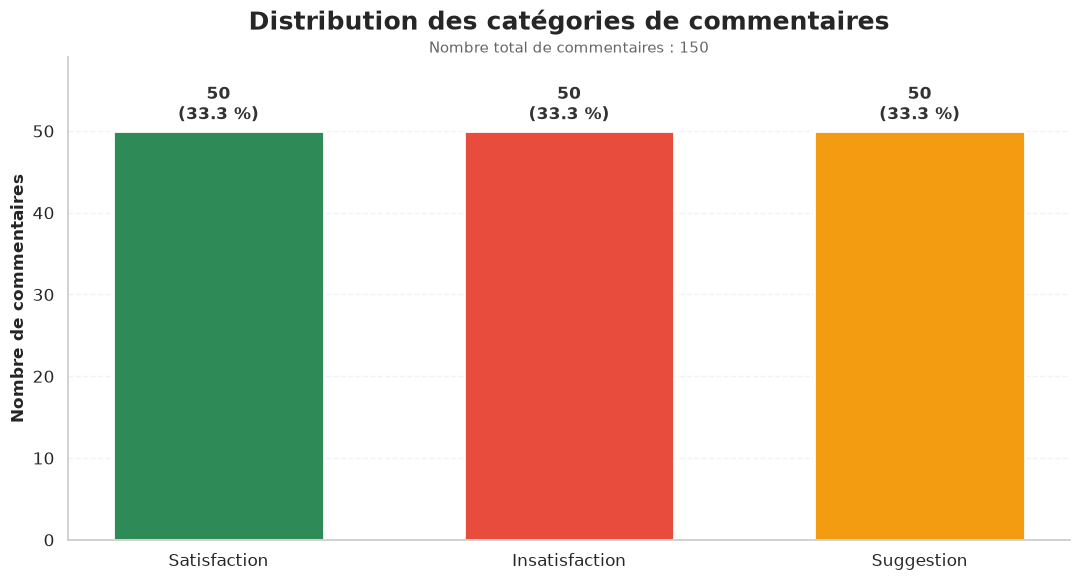

In [91]:
# ==============================
# Distribution des catégories
# ==============================

import matplotlib.pyplot as plt
import seaborn as sns

# Ordre des catégories
categories = ["Satisfaction", "Insatisfaction", "Suggestion"]

# Palette personnalisée
colors = {
    "Satisfaction": "#2E8B57",      # Vert
    "Insatisfaction": "#E74C3C",     # Rouge
    "Suggestion": "#F39C12"          # Orange
}

# Comptage des catégories
counts = df[TARGET_COLUMN].value_counts().reindex(categories, fill_value=0)

# Pourcentages
percentages = counts / counts.sum() * 100

# Style
sns.set_theme(
    style="whitegrid",
    font_scale=1.1
)

# Création de la figure
fig, ax = plt.subplots(figsize=(11, 6))

# Barres
bars = ax.bar(
    counts.index,
    counts.values,
    color=[colors[cat] for cat in counts.index],
    width=0.6,
    edgecolor="white",
    linewidth=2
)

# Titre
ax.set_title(
    "Distribution des catégories de commentaires",
    fontsize=18,
    fontweight="bold",
    pad=20
)

# Sous-titre
ax.text(
    0.5,
    1.01,
    f"Nombre total de commentaires : {counts.sum():,}",
    transform=ax.transAxes,
    ha="center",
    fontsize=11,
    color="#666666"
)

# Labels
ax.set_xlabel("")
ax.set_ylabel(
    "Nombre de commentaires",
    fontsize=12,
    fontweight="bold"
)

# Valeurs + pourcentages au-dessus des barres
for bar, count, percentage in zip(
    bars,
    counts.values,
    percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + counts.max() * 0.015,
        f"{count:,}\n({percentage:.1f} %)",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="#333333"
    )

# Nettoyage des axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Grille uniquement horizontale
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)
ax.grid(axis="x", visible=False)

# Limite supérieure pour laisser de l'espace aux labels
ax.set_ylim(0, counts.max() * 1.18)

# Mise en page
plt.tight_layout()

# Affichage
plt.show()


### Observation

Les trois catégories sont représentées par un nombre identique d'observations.

Le dataset est donc équilibré entre les classes, avec 50 commentaires pour chacune des catégories.

Cette caractéristique est favorable à l'apprentissage d'un modèle de classification et ne nécessite pas, à ce stade, de stratégie particulière de rééquilibrage des classes.

### 5.2 Exemples de commentaires par catégorie

Une inspection qualitative des commentaires permet d'identifier les caractéristiques linguistiques associées aux différentes classes.

In [92]:
for category in ["Satisfaction", "Insatisfaction", "Suggestion"]:

    print("\n" + "=" * 80)
    print(f"CATÉGORIE : {category}")
    print("=" * 80)

    examples = (
        df[df[TARGET_COLUMN] == category][[ID_COLUMN, TEXT_COLUMN]]
        .head(5)
    )

    display(examples)


CATÉGORIE : Satisfaction


,id,texte
7,8,J'ai été agréablement surpris par la rapidité du traitement.
8,9,"Bonne expérience globale, les choses évoluent positivement."
9,10,Le personnel fait preuve de beaucoup de professionnalisme.
12,13,Le service a été rapide et le personnel très accueillant.
15,16,"Le numérique au service des citoyens, c'est une excellente chose."



CATÉGORIE : Insatisfaction


,id,texte
0,1,Manque total de communication entre les services.
4,5,Le formulaire en ligne plante au moment de la soumission.
5,6,Le personnel semble débordé et les citoyens en pâtissent.
10,11,Le site web est inaccessible depuis plusieurs jours.
11,12,Traitement discriminatoire selon la tête du client.



CATÉGORIE : Suggestion


,id,texte
1,2,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.
2,3,Envoyer des SMS de confirmation lors de chaque étape du traitement.
3,4,Prévoir des interprètes pour les citoyens ne parlant pas le français.
6,7,Former les agents sur les droits des usagers pour un meilleur respect.
13,14,Numériser les archives pour retrouver rapidement les anciens dossiers.


## 6. Analyse de la longueur des commentaires

La longueur des commentaires peut constituer une caractéristique intéressante du corpus.

Nous calculons ici le nombre de caractères de chaque commentaire.

In [93]:
df["longueur_texte"] = df[TEXT_COLUMN].str.len()

display(
    df[[TEXT_COLUMN, "longueur_texte"]].head(10)
)

,texte,longueur_texte
0,Manque total de communication entre les services.,49
1,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,75
2,Envoyer des SMS de confirmation lors de chaque étape du traitement.,67
3,Prévoir des interprètes pour les citoyens ne parlant pas le français.,69
4,Le formulaire en ligne plante au moment de la soumission.,57
5,Le personnel semble débordé et les citoyens en pâtissent.,57
6,Former les agents sur les droits des usagers pour un meilleur respect.,70
7,J'ai été agréablement surpris par la rapidité du traitement.,60
8,"Bonne expérience globale, les choses évoluent positivement.",59
9,Le personnel fait preuve de beaucoup de professionnalisme.,58


In [94]:
length_statistics = (
    df.groupby(TARGET_COLUMN)["longueur_texte"]
      .agg(
          nombre="count",
          moyenne="mean",
          mediane="median",
          minimum="min",
          maximum="max"
      )
      .round(2)
)

display(length_statistics)

,nombre,moyenne,mediane,minimum,maximum
categorie,,,,,
Insatisfaction,50,57.76,57.0,34,78
Satisfaction,50,57.40,59.0,27,76
Suggestion,50,69.82,70.0,58,84


In [95]:
global_mean_length = df["longueur_texte"].mean()

print(
    f"Longueur moyenne globale des commentaires : "
    f"{global_mean_length:.2f} caractères"
)

Longueur moyenne globale des commentaires : 61.66 caractères


### 6.1 Distribution de la longueur par catégorie

Le boxplot permet de comparer la distribution des longueurs entre les trois catégories et d'identifier d'éventuelles valeurs atypiques.

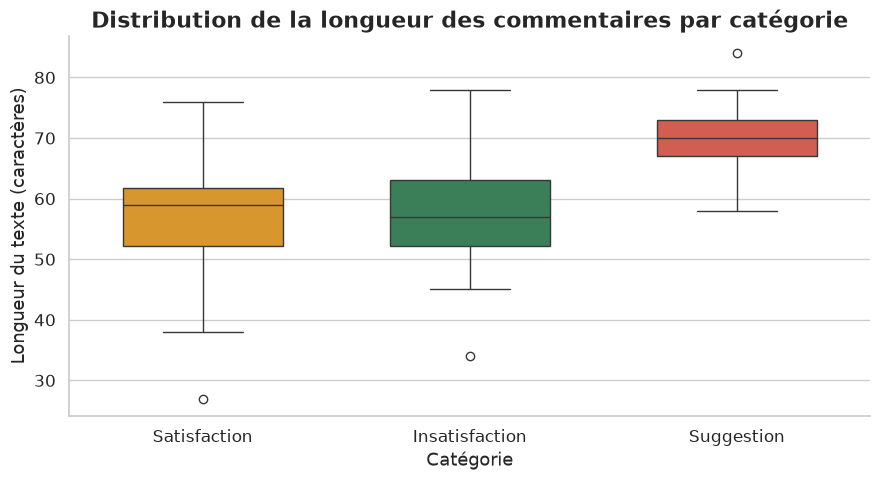

In [96]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=TARGET_COLUMN,
    y="longueur_texte",
    hue=TARGET_COLUMN,
    order=["Satisfaction", "Insatisfaction", "Suggestion"],
    palette=["#2E8B57", "#E74C3C", "#F39C12"],
    width=0.6,
    legend=False
)

plt.title(
    "Distribution de la longueur des commentaires par catégorie",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Catégorie")
plt.ylabel("Longueur du texte (caractères)")

sns.despine()

plt.tight_layout()
plt.show()


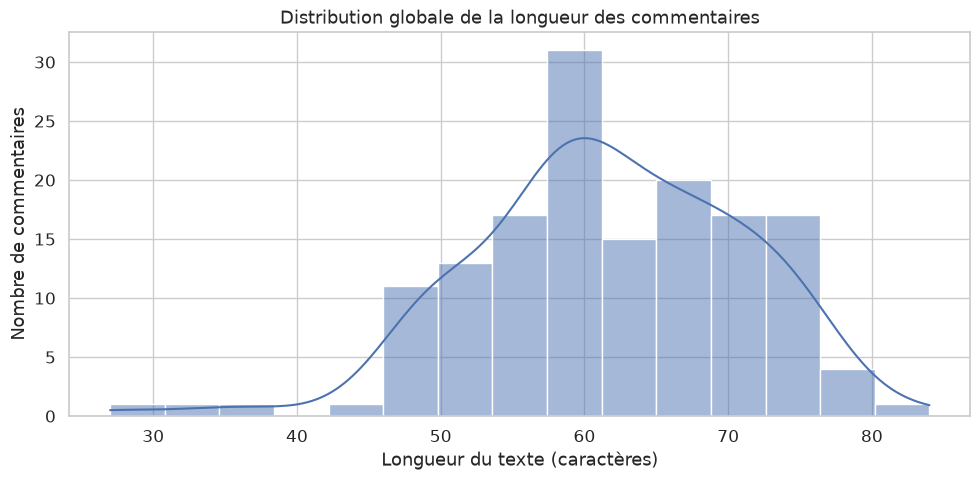

In [97]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="longueur_texte",
    bins=15,
    kde=True
)

plt.title("Distribution globale de la longueur des commentaires")
plt.xlabel("Longueur du texte (caractères)")
plt.ylabel("Nombre de commentaires")

plt.tight_layout()
plt.show()

## 8. Présence de termes en éwé/mina

Le sujet indique que les commentaires sont majoritairement en français mais peuvent contenir des insertions en éwé ou en mina.

Nous recherchons donc quelques exemples explicitement présents dans le corpus afin d'évaluer leur forme avant de définir la stratégie de prétraitement.

In [98]:
keywords_local = [
    "Yèvu",
    "nyuie",
    "hafi",
    "Mele",
    "mègbe",
    "Akpe",
    "wò"
]

pattern = "|".join(map(re.escape, keywords_local))

local_language_examples = df[
    df[TEXT_COLUMN].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )
]

display(
    local_language_examples[
        [ID_COLUMN, TEXT_COLUMN, TARGET_COLUMN]
    ]
)

,id,texte,categorie
72,73,Yèvu service la nyuie hafi!,Satisfaction
130,131,"Mele via o, service la mègbe trop!",Insatisfaction
138,139,"Akpe na wò, service très professionnel et efficace.",Satisfaction


### Observation

Le corpus contient effectivement des commentaires intégrant des termes ou expressions qui ne sont pas exclusivement en français.

Par exemple, certaines observations contiennent des expressions telles que « Yèvu service la nyuie hafi », « Mele via o, service la mègbe trop » ou « Akpe na wò ».

Ces éléments devront être pris en compte lors du prétraitement. L'objectif sera de réduire le bruit textuel sans supprimer des tokens potentiellement informatifs pour la classification.

## 9. Synthèse statistique

In [99]:
summary = pd.DataFrame({
    "Indicateur": [
        "Nombre total de commentaires",
        "Nombre de catégories",
        "Nombre de commentaires Satisfaction",
        "Nombre de commentaires Insatisfaction",
        "Nombre de commentaires Suggestion",
        "Nombre de valeurs manquantes",
        "Nombre de doublons complets",
        "Longueur moyenne globale"
    ],
    "Valeur": [
        len(df),
        df[TARGET_COLUMN].nunique(),
        (df[TARGET_COLUMN] == "Satisfaction").sum(),
        (df[TARGET_COLUMN] == "Insatisfaction").sum(),
        (df[TARGET_COLUMN] == "Suggestion").sum(),
        df.isna().sum().sum(),
        df.duplicated().sum(),
        round(df["longueur_texte"].mean(), 2)
    ]
})

display(summary)

,Indicateur,Valeur
0,Nombre total de commentaires,150.00
1,Nombre de catégories,3.00
2,Nombre de commentaires Satisfaction,50.00
3,Nombre de commentaires Insatisfaction,50.00
4,Nombre de commentaires Suggestion,50.00
5,Nombre de valeurs manquantes,0.00
6,Nombre de doublons complets,0.00
7,Longueur moyenne globale,61.66


# 11. Prétraitement des textes

Le prétraitement constitue une étape importante du pipeline NLP.

L'objectif est de réduire le bruit présent dans les textes tout en conservant les informations susceptibles d'être utiles à la classification.

Les principales opérations appliquées sont :

- normalisation Unicode ;
- conversion en minuscules ;
- suppression des chiffres ;
- suppression de la ponctuation et de certains caractères spéciaux ;
- normalisation des espaces ;
- suppression des stopwords français non informatifs ;
- conservation des termes inconnus pouvant appartenir à l'éwé ou au mina.

Une attention particulière est portée au contexte multilingue du corpus.

### 11.1 Stratégie de prétraitement

Un nettoyage trop agressif peut être problématique dans un corpus multilingue.

Par exemple, un terme qui n'est pas présent dans une liste de mots français ne doit pas automatiquement être considéré comme du bruit. Il peut s'agir d'un mot ou d'une expression en éwé/mina.

Nous choisissons donc de ne pas supprimer les mots inconnus uniquement parce qu'ils ne figurent pas dans le vocabulaire français.

Cette stratégie permet de préserver les informations linguistiques potentiellement discriminantes.

In [100]:
df_preprocessed = df.copy()

print(f"Nombre de textes à traiter : {len(df_preprocessed)}")

Nombre de textes à traiter : 150


### 11.2 Normalisation Unicode

Les textes peuvent contenir différents caractères Unicode représentant visuellement des caractères similaires.

Une normalisation Unicode permet de rendre la représentation textuelle plus cohérente avant les étapes suivantes.

In [101]:
def normalize_unicode(text):
    return unicodedata.normalize("NFKC", text)

In [102]:
df_preprocessed["texte_unicode"] = (
    df_preprocessed["texte"]
    .apply(normalize_unicode)
)

display(
    df_preprocessed[
        ["texte", "texte_unicode"]
    ].head(10)
)

,texte,texte_unicode
0,Manque total de communication entre les services.,Manque total de communication entre les services.
1,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.
2,Envoyer des SMS de confirmation lors de chaque étape du traitement.,Envoyer des SMS de confirmation lors de chaque étape du traitement.
3,Prévoir des interprètes pour les citoyens ne parlant pas le français.,Prévoir des interprètes pour les citoyens ne parlant pas le français.
4,Le formulaire en ligne plante au moment de la soumission.,Le formulaire en ligne plante au moment de la soumission.
5,Le personnel semble débordé et les citoyens en pâtissent.,Le personnel semble débordé et les citoyens en pâtissent.
6,Former les agents sur les droits des usagers pour un meilleur respect.,Former les agents sur les droits des usagers pour un meilleur respect.
7,J'ai été agréablement surpris par la rapidité du traitement.,J'ai été agréablement surpris par la rapidité du traitement.
8,"Bonne expérience globale, les choses évoluent positivement.","Bonne expérience globale, les choses évoluent positivement."
9,Le personnel fait preuve de beaucoup de professionnalisme.,Le personnel fait preuve de beaucoup de professionnalisme.


### 11.3 Conversion en minuscules

La classification textuelle ne doit généralement pas considérer comme différents les mots qui ne diffèrent que par leur capitalisation.

Par exemple :

`Service`, `service` et `SERVICE`

doivent être considérés comme le même terme.

In [103]:
def to_lowercase(text):
    return text.lower()

In [104]:
df_preprocessed["texte_lower"] = (
    df_preprocessed["texte_unicode"]
    .apply(to_lowercase)
)

display(
    df_preprocessed[
        ["texte_unicode", "texte_lower"]
    ].head(10)
)

,texte_unicode,texte_lower
0,Manque total de communication entre les services.,manque total de communication entre les services.
1,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.
2,Envoyer des SMS de confirmation lors de chaque étape du traitement.,envoyer des sms de confirmation lors de chaque étape du traitement.
3,Prévoir des interprètes pour les citoyens ne parlant pas le français.,prévoir des interprètes pour les citoyens ne parlant pas le français.
4,Le formulaire en ligne plante au moment de la soumission.,le formulaire en ligne plante au moment de la soumission.
5,Le personnel semble débordé et les citoyens en pâtissent.,le personnel semble débordé et les citoyens en pâtissent.
6,Former les agents sur les droits des usagers pour un meilleur respect.,former les agents sur les droits des usagers pour un meilleur respect.
7,J'ai été agréablement surpris par la rapidité du traitement.,j'ai été agréablement surpris par la rapidité du traitement.
8,"Bonne expérience globale, les choses évoluent positivement.","bonne expérience globale, les choses évoluent positivement."
9,Le personnel fait preuve de beaucoup de professionnalisme.,le personnel fait preuve de beaucoup de professionnalisme.


### 11.4 Suppression des chiffres

Les chiffres isolés ne semblent pas constituer une information centrale pour la classification des trois catégories dans ce corpus.

Ils sont donc supprimés afin de réduire le bruit lexical.

In [105]:
def remove_digits(text):
    return re.sub(r"\d+", " ", text)

In [106]:
df_preprocessed["texte_sans_chiffres"] = (
    df_preprocessed["texte_lower"]
    .apply(remove_digits)
)

display(
    df_preprocessed[
        ["texte_lower", "texte_sans_chiffres"]
    ].head(10)
)

,texte_lower,texte_sans_chiffres
0,manque total de communication entre les services.,manque total de communication entre les services.
1,il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.
2,envoyer des sms de confirmation lors de chaque étape du traitement.,envoyer des sms de confirmation lors de chaque étape du traitement.
3,prévoir des interprètes pour les citoyens ne parlant pas le français.,prévoir des interprètes pour les citoyens ne parlant pas le français.
4,le formulaire en ligne plante au moment de la soumission.,le formulaire en ligne plante au moment de la soumission.
5,le personnel semble débordé et les citoyens en pâtissent.,le personnel semble débordé et les citoyens en pâtissent.
6,former les agents sur les droits des usagers pour un meilleur respect.,former les agents sur les droits des usagers pour un meilleur respect.
7,j'ai été agréablement surpris par la rapidité du traitement.,j'ai été agréablement surpris par la rapidité du traitement.
8,"bonne expérience globale, les choses évoluent positivement.","bonne expérience globale, les choses évoluent positivement."
9,le personnel fait preuve de beaucoup de professionnalisme.,le personnel fait preuve de beaucoup de professionnalisme.


### 11.5 Gestion de la ponctuation

La ponctuation est supprimée afin de réduire les variations inutiles dans la représentation des textes.

Les caractères alphabétiques accentués sont cependant conservés, car ils sont fréquents dans le français utilisé dans le corpus.

In [107]:
def remove_punctuation(text):
    return re.sub(r"[^\w\sÀ-ÿ]", " ", text)

In [108]:
df_preprocessed["texte_sans_ponctuation"] = (
    df_preprocessed["texte_sans_chiffres"]
    .apply(remove_punctuation)
)

display(
    df_preprocessed[
        ["texte_sans_chiffres", "texte_sans_ponctuation"]
    ].head(10)
)

,texte_sans_chiffres,texte_sans_ponctuation
0,manque total de communication entre les services.,manque total de communication entre les services
1,il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,il serait bien de proposer des tutoriels vidéo pour les démarches en ligne
2,envoyer des sms de confirmation lors de chaque étape du traitement.,envoyer des sms de confirmation lors de chaque étape du traitement
3,prévoir des interprètes pour les citoyens ne parlant pas le français.,prévoir des interprètes pour les citoyens ne parlant pas le français
4,le formulaire en ligne plante au moment de la soumission.,le formulaire en ligne plante au moment de la soumission
5,le personnel semble débordé et les citoyens en pâtissent.,le personnel semble débordé et les citoyens en pâtissent
6,former les agents sur les droits des usagers pour un meilleur respect.,former les agents sur les droits des usagers pour un meilleur respect
7,j'ai été agréablement surpris par la rapidité du traitement.,j ai été agréablement surpris par la rapidité du traitement
8,"bonne expérience globale, les choses évoluent positivement.",bonne expérience globale les choses évoluent positivement
9,le personnel fait preuve de beaucoup de professionnalisme.,le personnel fait preuve de beaucoup de professionnalisme


### 11.6 Normalisation des espaces

La suppression de caractères peut générer plusieurs espaces consécutifs.

Nous les remplaçons par un seul espace et supprimons les espaces en début et fin de texte.

In [109]:
def normalize_spaces(text):
    return re.sub(r"\s+", " ", text).strip()

In [110]:
df_preprocessed["texte_normalise"] = (
    df_preprocessed["texte_sans_ponctuation"]
    .apply(normalize_spaces)
)

display(
    df_preprocessed[
        ["texte", "texte_normalise"]
    ].head(10)
)

,texte,texte_normalise
0,Manque total de communication entre les services.,manque total de communication entre les services
1,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,il serait bien de proposer des tutoriels vidéo pour les démarches en ligne
2,Envoyer des SMS de confirmation lors de chaque étape du traitement.,envoyer des sms de confirmation lors de chaque étape du traitement
3,Prévoir des interprètes pour les citoyens ne parlant pas le français.,prévoir des interprètes pour les citoyens ne parlant pas le français
4,Le formulaire en ligne plante au moment de la soumission.,le formulaire en ligne plante au moment de la soumission
5,Le personnel semble débordé et les citoyens en pâtissent.,le personnel semble débordé et les citoyens en pâtissent
6,Former les agents sur les droits des usagers pour un meilleur respect.,former les agents sur les droits des usagers pour un meilleur respect
7,J'ai été agréablement surpris par la rapidité du traitement.,j ai été agréablement surpris par la rapidité du traitement
8,"Bonne expérience globale, les choses évoluent positivement.",bonne expérience globale les choses évoluent positivement
9,Le personnel fait preuve de beaucoup de professionnalisme.,le personnel fait preuve de beaucoup de professionnalisme


In [111]:
import nltk

nltk.download("stopwords")

/home/maximedefa/donnees/projets/data_nlp/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/maximedefa/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/maximedefa/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [112]:
from nltk.corpus import stopwords

french_stopwords = set(stopwords.words("french"))

print(f"Nombre de stopwords français : {len(french_stopwords)}")

Nombre de stopwords français : 157


### 11.7 Gestion des stopwords et de la négation

Les stopwords français sont généralement peu informatifs pour une tâche de classification.

Cependant, certaines formes de négation peuvent modifier complètement le sens d'un commentaire. Elles sont donc conservées afin de ne pas perdre une information importante pour distinguer notamment la satisfaction de l'insatisfaction.

In [113]:
negation_words = {
    "ne",
    "pas",
    "plus",
    "jamais",
    "aucun",
    "aucune",
    "sans"
}

french_stopwords_filtered = (
    french_stopwords - negation_words
)

print("Stopwords français initiaux :", len(french_stopwords))
print("Stopwords après conservation des négations :",
      len(french_stopwords_filtered))

Stopwords français initiaux : 157
Stopwords après conservation des négations : 155


In [114]:
def remove_french_stopwords(text):
    tokens = text.split()

    filtered_tokens = [
        token
        for token in tokens
        if token not in french_stopwords_filtered
    ]

    return " ".join(filtered_tokens)

In [115]:
df_preprocessed["texte_sans_stopwords"] = (
    df_preprocessed["texte_normalise"]
    .apply(remove_french_stopwords)
)

In [116]:
display(
    df_preprocessed[
        [
            "texte",
            "texte_normalise",
            "texte_sans_stopwords"
        ]
    ].head(15)
)

,texte,texte_normalise,texte_sans_stopwords
0,Manque total de communication entre les services.,manque total de communication entre les services,manque total communication entre services
1,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,il serait bien de proposer des tutoriels vidéo pour les démarches en ligne,bien proposer tutoriels vidéo démarches ligne
2,Envoyer des SMS de confirmation lors de chaque étape du traitement.,envoyer des sms de confirmation lors de chaque étape du traitement,envoyer sms confirmation lors chaque étape traitement
3,Prévoir des interprètes pour les citoyens ne parlant pas le français.,prévoir des interprètes pour les citoyens ne parlant pas le français,prévoir interprètes citoyens ne parlant pas français
4,Le formulaire en ligne plante au moment de la soumission.,le formulaire en ligne plante au moment de la soumission,formulaire ligne plante moment soumission
5,Le personnel semble débordé et les citoyens en pâtissent.,le personnel semble débordé et les citoyens en pâtissent,personnel semble débordé citoyens pâtissent
6,Former les agents sur les droits des usagers pour un meilleur respect.,former les agents sur les droits des usagers pour un meilleur respect,former agents droits usagers meilleur respect
7,J'ai été agréablement surpris par la rapidité du traitement.,j ai été agréablement surpris par la rapidité du traitement,agréablement surpris rapidité traitement
8,"Bonne expérience globale, les choses évoluent positivement.",bonne expérience globale les choses évoluent positivement,bonne expérience globale choses évoluent positivement
9,Le personnel fait preuve de beaucoup de professionnalisme.,le personnel fait preuve de beaucoup de professionnalisme,personnel fait preuve beaucoup professionnalisme


In [117]:
negation_examples = df_preprocessed[
    df_preprocessed["texte_normalise"].str.contains(
        r"\b(pas|ne|jamais|aucun|aucune|sans)\b",
        regex=True,
        na=False
    )
]

display(
    negation_examples[
        [
            "texte",
            "texte_sans_stopwords"
        ]
    ].head(15)
)

/tmp/ipykernel_201413/2814416103.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_preprocessed["texte_normalise"].str.contains(


,texte,texte_sans_stopwords
3,Prévoir des interprètes pour les citoyens ne parlant pas le français.,prévoir interprètes citoyens ne parlant pas français
22,"Système de file d'attente chaotique, pas de respect de l'ordre d'arrivée.",système file attente chaotique pas respect ordre arrivée
29,Le délai légal n'est pas respecté et personne n'en rend compte.,délai légal pas respecté personne rend compte
30,Mon dossier traîne depuis 6 semaines sans réponse.,dossier traîne depuis semaines sans réponse
31,Aucune prise en charge des personnes à mobilité réduite.,aucune prise charge personnes mobilité réduite
37,Trois mois d'attente pour un résultat qui ne correspond pas à ma demande.,trois mois attente résultat ne correspond pas demande
40,Aucune indication claire pour savoir où aller dans le bâtiment.,aucune indication claire savoir où aller bâtiment
42,"Aucune solution proposée face à mon problème, juste 'revenez demain'.",aucune solution proposée face problème juste revenez demain
45,Agents absents la moitié du temps sans remplacement prévu.,agents absents moitié temps sans remplacement prévu
49,Je n'ai reçu aucun accusé de réception de ma demande.,reçu aucun accusé réception demande


### 11.8 Gestion des termes éwé/mina

Le corpus contient quelques commentaires comportant des termes ou expressions en éwé/mina.

Nous ne disposons pas, dans le dataset fourni, d'un lexique suffisamment complet permettant d'identifier automatiquement tous ces termes.

Plutôt que de supprimer les mots inconnus du vocabulaire français, nous choisissons donc de les conserver.

Cette approche permet au modèle TF-IDF d'apprendre directement les termes qui apparaissent dans le corpus et qui pourraient être associés à une catégorie particulière.

In [118]:
local_terms = [
    "yèvu",
    "nyuie",
    "hafi",
    "mele",
    "mègbe",
    "akpe",
    "wò"
]

for term in local_terms:
    matches = df_preprocessed[
        df_preprocessed["texte_sans_stopwords"]
        .str.contains(
            rf"\b{re.escape(term)}\b",
            case=False,
            regex=True,
            na=False
        )
    ]

    if len(matches) > 0:
        print(f"\nTerme : {term}")
        display(
            matches[
                ["texte", "texte_sans_stopwords", "categorie"]
            ]
        )


Terme : yèvu


,texte,texte_sans_stopwords,categorie
72,Yèvu service la nyuie hafi!,yèvu service nyuie hafi,Satisfaction



Terme : nyuie


,texte,texte_sans_stopwords,categorie
72,Yèvu service la nyuie hafi!,yèvu service nyuie hafi,Satisfaction



Terme : hafi


...

,texte,texte_sans_stopwords,categorie
130,"Mele via o, service la mègbe trop!",mele via o service mègbe trop,Insatisfaction



Terme : akpe


,texte,texte_sans_stopwords,categorie
138,"Akpe na wò, service très professionnel et efficace.",akpe na wò service très professionnel efficace,Satisfaction



Terme : wò


,texte,texte_sans_stopwords,categorie
138,"Akpe na wò, service très professionnel et efficace.",akpe na wò service très professionnel efficace,Satisfaction


In [119]:
df_preprocessed["texte_propre"] = (
    df_preprocessed["texte"]
    .apply(normalize_unicode)
    .apply(to_lowercase)
    .apply(remove_digits)
    .apply(remove_punctuation)
    .apply(normalize_spaces)
    .apply(remove_french_stopwords)
)

### 11.9 Comparaison avant et après prétraitement

Afin de contrôler l'effet du nettoyage, nous comparons quelques commentaires avant et après prétraitement.

In [120]:
comparison = df_preprocessed[
    ["texte", "texte_propre", "categorie"]
].copy()

display(comparison.head(20))

,texte,texte_propre,categorie
0,Manque total de communication entre les services.,manque total communication entre services,Insatisfaction
1,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,bien proposer tutoriels vidéo démarches ligne,Suggestion
2,Envoyer des SMS de confirmation lors de chaque étape du traitement.,envoyer sms confirmation lors chaque étape traitement,Suggestion
3,Prévoir des interprètes pour les citoyens ne parlant pas le français.,prévoir interprètes citoyens ne parlant pas français,Suggestion
4,Le formulaire en ligne plante au moment de la soumission.,formulaire ligne plante moment soumission,Insatisfaction
5,Le personnel semble débordé et les citoyens en pâtissent.,personnel semble débordé citoyens pâtissent,Insatisfaction
6,Former les agents sur les droits des usagers pour un meilleur respect.,former agents droits usagers meilleur respect,Suggestion
7,J'ai été agréablement surpris par la rapidité du traitement.,agréablement surpris rapidité traitement,Satisfaction
8,"Bonne expérience globale, les choses évoluent positivement.",bonne expérience globale choses évoluent positivement,Satisfaction
9,Le personnel fait preuve de beaucoup de professionnalisme.,personnel fait preuve beaucoup professionnalisme,Satisfaction


In [121]:
df_preprocessed["longueur_avant"] = (
    df_preprocessed["texte"].str.len()
)

df_preprocessed["longueur_apres"] = (
    df_preprocessed["texte_propre"].str.len()
)

df_preprocessed["reduction"] = (
    1 -
    df_preprocessed["longueur_apres"]
    / df_preprocessed["longueur_avant"]
)

display(
    df_preprocessed[
        [
            "categorie",
            "longueur_avant",
            "longueur_apres",
            "reduction"
        ]
    ].head(10)
)

,categorie,longueur_avant,longueur_apres,reduction
0,Insatisfaction,49,41,0.163265
1,Suggestion,75,45,0.400000
2,Suggestion,67,53,0.208955
3,Suggestion,69,52,0.246377
4,Insatisfaction,57,41,0.280702
5,Insatisfaction,57,43,0.245614
6,Suggestion,70,45,0.357143
7,Satisfaction,60,40,0.333333
8,Satisfaction,59,53,0.101695
9,Satisfaction,58,48,0.172414


In [122]:
print(
    f"Réduction moyenne de longueur : "
    f"{df_preprocessed['reduction'].mean() * 100:.2f}%"
)

Réduction moyenne de longueur : 24.18%


In [123]:
empty_after_preprocessing = df_preprocessed[
    df_preprocessed["texte_propre"].str.strip().eq("")
]

print(
    "Nombre de textes devenus vides après preprocessing :",
    len(empty_after_preprocessing)
)

Nombre de textes devenus vides après preprocessing : 0


## 12. Conclusion du prétraitement

Le prétraitement mis en place permet de réduire le bruit textuel tout en conservant les informations importantes pour la classification.

Les textes ont été :

- normalisés au niveau Unicode ;
- convertis en minuscules ;
- débarrassés des chiffres et de la ponctuation non informative ;
- normalisés au niveau des espaces ;
- nettoyés des stopwords français non informatifs.

Les marqueurs de négation ont volontairement été conservés, car ils peuvent modifier fortement le sens d'un commentaire.

Les termes ne correspondant pas au vocabulaire français n'ont pas été supprimés automatiquement. Cette décision permet notamment de conserver les éventuels termes en éwé/mina présents dans le corpus.

Le texte obtenu dans `texte_propre` sera utilisé lors de l'étape suivante pour la vectorisation et la modélisation.

# 13. Préparation des données et modélisation

Cette section prépare les données pour l'apprentissage automatique.

Le pipeline est le suivant :

1. séparation des données en ensembles d'entraînement et de test ;
2. vectorisation des textes avec TF-IDF ;
3. entraînement de plusieurs modèles de classification ;
4. comparaison de leurs performances.

La séparation est stratifiée afin de conserver la même proportion de catégories dans les deux ensembles.

In [124]:
from sklearn.model_selection import train_test_split

X = df_preprocessed["texte_propre"]
y = df_preprocessed["categorie"]

print("Nombre de textes :", len(X))
print("Nombre de labels :", len(y))

Nombre de textes : 150
Nombre de labels : 150


In [125]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Train : {len(X_train)}")
print(f"Test  : {len(X_test)}")

Train : 120
Test  : 30


In [126]:
print("Distribution TRAIN")
display(y_train.value_counts())

print("\nDistribution TEST")
display(y_test.value_counts())

Distribution TRAIN


categorie
Insatisfaction    40
Suggestion        40
Satisfaction      40
Name: count, dtype: int64


Distribution TEST


categorie
Insatisfaction    10
Suggestion        10
Satisfaction      10
Name: count, dtype: int64

### Observation

La séparation stratifiée conserve une représentation équilibrée des trois catégories dans les ensembles d'entraînement et de test.

## 14. Vectorisation TF-IDF

Les modèles de machine learning ne peuvent pas directement exploiter les textes bruts.

Nous utilisons donc TF-IDF afin de transformer chaque commentaire en représentation numérique.

Nous utilisons des n-grammes de mots `(1, 2)` afin de prendre en compte à la fois les mots individuels et certaines associations de deux mots.

In [127]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Taille de X_train :", X_train_tfidf.shape)
print("Taille de X_test  :", X_test_tfidf.shape)

Taille de X_train : (120, 991)
Taille de X_test  : (30, 991)


In [128]:
feature_names = vectorizer.get_feature_names_out()

print(f"Nombre de features TF-IDF : {len(feature_names)}")

print("\nPremières features :")
print(feature_names[:30])

Nombre de features TF-IDF : 991

Premières features :
['absents' 'absents moitié' 'accessible' 'accompagnement'
 'accompagnement personnalisé' 'accueil' 'accueil bienveillant'
 'accueil froid' 'accueil traitement' 'accueil usagers' 'accueillant'
 'accusé' 'accusé réception' 'accès' 'accès wi' 'acte' 'acte naissance'
 'administration' 'administratives' 'affichage' 'afficher'
 'afficher clairement' 'affichés' 'affichés ne' 'agents' 'agents absents'
 'agents accueil' 'agents bilingues' 'agents droits' 'agents mobiles']


In [129]:
local_features = [
    feature for feature in feature_names
    if any(
        term in feature
        for term in ["yèvu", "nyuie", "hafi", "mele", "mègbe", "akpe"]
    )
]

print("Features locales trouvées :")
print(local_features)

Features locales trouvées :
['mele', 'mele via', 'mègbe', 'mègbe trop', 'service mègbe']


## 15. Modèle 1 — Régression logistique

La régression logistique est utilisée comme premier modèle de référence pour la classification multiclasses.

Elle constitue un modèle simple, rapide et particulièrement adapté aux représentations TF-IDF.

In [130]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

logistic_model.fit(X_train_tfidf, y_train)

y_pred_logistic = logistic_model.predict(X_test_tfidf)

print("Modèle Logistic Regression entraîné.")

Modèle Logistic Regression entraîné.


## 16. Modèle 2 — Linear SVM

Nous utilisons également un classifieur Linear SVM.

Les modèles linéaires sont souvent efficaces pour les problèmes de classification de documents représentés avec TF-IDF.

In [131]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    random_state=RANDOM_STATE
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("Modèle Linear SVM entraîné.")

Modèle Linear SVM entraîné.


## 17. Évaluation des modèles

Les performances sont évaluées avec :

- accuracy ;
- precision ;
- recall ;
- F1-score ;
- matrice de confusion.

Le F1-score macro est particulièrement pertinent ici car il donne le même poids à chacune des trois catégories.

In [132]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [133]:
def evaluate_model(name, y_true, y_pred):
    return {
        "Modèle": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

In [134]:
results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_logistic
    ),
    evaluate_model(
        "Linear SVM",
        y_test,
        y_pred_svm
    )
])

display(
    results.round(4)
)

,Modèle,Accuracy,Precision macro,Recall macro,F1 macro
0,Logistic Regression,0.7333,0.7418,0.7333,0.7363
1,Linear SVM,0.7667,0.7721,0.7667,0.7680


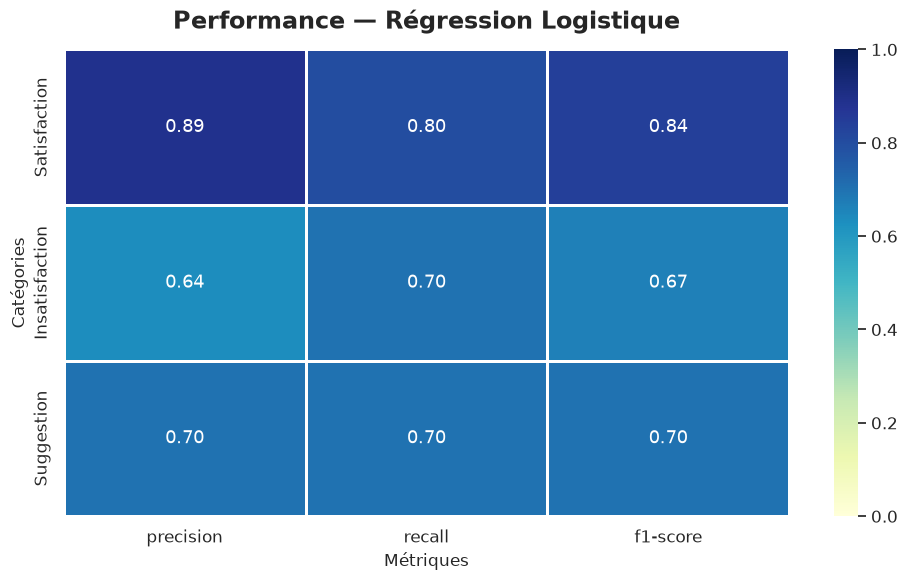

In [135]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

report = classification_report(
    y_test,
    y_pred_logistic,
    output_dict=True,
    zero_division=0
)

# Transformer le rapport en DataFrame
report_df = pd.DataFrame(report).transpose()

# Garder uniquement les classes
classes = ["Satisfaction", "Insatisfaction", "Suggestion"]
metrics_df = report_df.loc[classes, ["precision", "recall", "f1-score"]]

# Figure
plt.figure(figsize=(10, 6))

sns.heatmap(
    metrics_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=1,
    linecolor="white"
)

plt.title(
    "Performance — Régression Logistique",
    fontsize=17,
    fontweight="bold",
    pad=15
)

plt.xlabel("Métriques", fontsize=12)
plt.ylabel("Catégories", fontsize=12)

plt.tight_layout()
plt.show()


## 18. Matrices de confusion

La matrice de confusion permet d'identifier les catégories correctement classées et les confusions entre catégories.

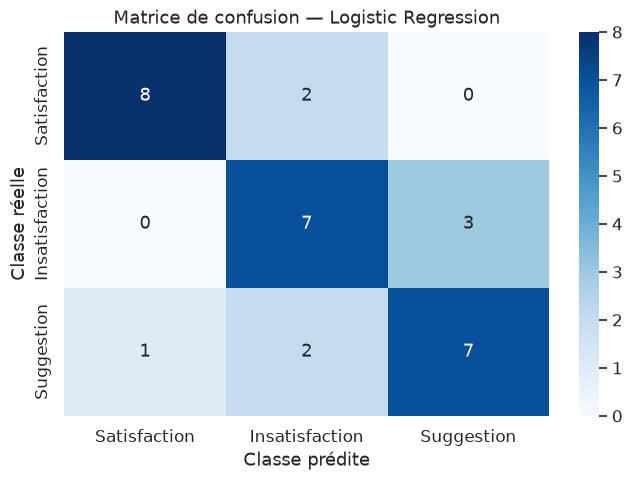

In [136]:
from sklearn.metrics import confusion_matrix

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=["Satisfaction", "Insatisfaction", "Suggestion"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Satisfaction", "Insatisfaction", "Suggestion"],
    yticklabels=["Satisfaction", "Insatisfaction", "Suggestion"]
)

plt.title("Matrice de confusion — Logistic Regression")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

plt.tight_layout()
plt.show()

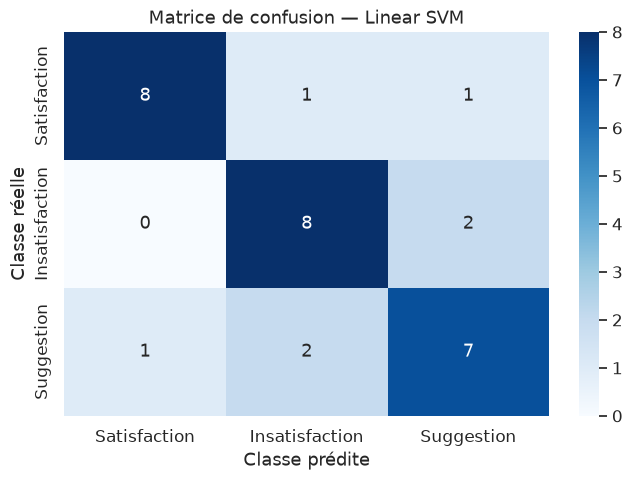

In [137]:
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=["Satisfaction", "Insatisfaction", "Suggestion"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Satisfaction", "Insatisfaction", "Suggestion"],
    yticklabels=["Satisfaction", "Insatisfaction", "Suggestion"]
)

plt.title("Matrice de confusion — Linear SVM")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

plt.tight_layout()
plt.show()

In [138]:
errors = pd.DataFrame({
    "texte": X_test,
    "vraie_classe": y_test,
    "classe_predite": y_pred_svm
})

errors = errors[
    errors["vraie_classe"] != errors["classe_predite"]
]

print(f"Nombre d'erreurs : {len(errors)}")

display(errors)

Nombre d'erreurs : 7


,texte,vraie_classe,classe_predite
19,agent patient écoute préoccupations,Satisfaction,Suggestion
52,manque personnel visible seulement guichets ouverts,Insatisfaction,Suggestion
113,service numérique fonctionnel accessible depuis téléphone,Satisfaction,Insatisfaction
13,numériser archives retrouver rapidement anciens dossiers,Suggestion,Satisfaction
89,ouvrir guichet spécial personnes âgées handicapées,Suggestion,Insatisfaction
83,chatbot site officiel aiderait orienter usagers,Suggestion,Insatisfaction
49,reçu aucun accusé réception demande,Insatisfaction,Suggestion


In [139]:
display(
    errors[
        [
            "texte",
            "vraie_classe",
            "classe_predite"
        ]
    ].head(10)
)

,texte,vraie_classe,classe_predite
19,agent patient écoute préoccupations,Satisfaction,Suggestion
52,manque personnel visible seulement guichets ouverts,Insatisfaction,Suggestion
113,service numérique fonctionnel accessible depuis téléphone,Satisfaction,Insatisfaction
13,numériser archives retrouver rapidement anciens dossiers,Suggestion,Satisfaction
89,ouvrir guichet spécial personnes âgées handicapées,Suggestion,Insatisfaction
83,chatbot site officiel aiderait orienter usagers,Suggestion,Insatisfaction
49,reçu aucun accusé réception demande,Insatisfaction,Suggestion


### Interprétation

Les erreurs doivent être analysées individuellement plutôt que considérées uniquement à travers les métriques globales.

Certaines confusions peuvent être liées à des commentaires courts, à des formulations ambiguës ou au caractère multilingue de certaines observations.

## 20. Conclusion de la modélisation

Deux modèles linéaires ont été entraînés à partir d'une représentation TF-IDF :

- Logistic Regression ;
- Linear SVM.

Les deux modèles ont été évalués sur un ensemble de test indépendant représentant 20 % du corpus.

Les métriques obtenues permettent de comparer objectivement leurs performances sur les trois catégories.

L'analyse des matrices de confusion et des erreurs permet également d'identifier les catégories les plus difficiles à distinguer et les limites du modèle sur certains commentaires.

La suite consiste à interpréter les résultats et à identifier les pistes d'amélioration possibles.

# 21. Interprétation des résultats

Les performances obtenues permettent de comparer les deux approches de classification.

Cependant, les métriques globales ne suffisent pas à comprendre le comportement des modèles. Nous analysons donc également les prédictions incorrectes et les caractéristiques des termes utilisés par les modèles.

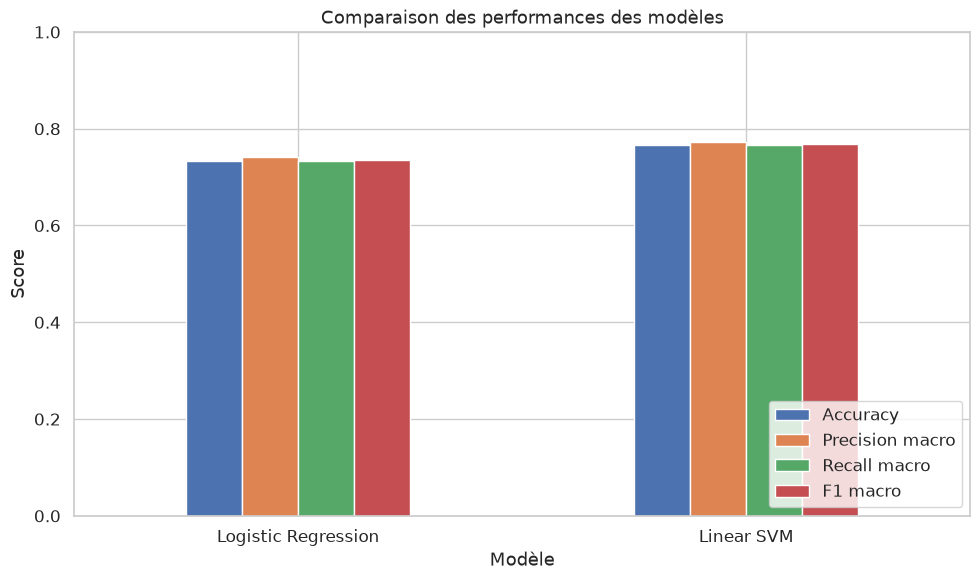

In [140]:
metrics_to_plot = [
    "Accuracy",
    "Precision macro",
    "Recall macro",
    "F1 macro"
]

results_plot = results.set_index("Modèle")[metrics_to_plot]

ax = results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparaison des performances des modèles")
plt.ylabel("Score")
plt.xlabel("Modèle")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [141]:
best_model_name = results.loc[
    results["F1 macro"].idxmax(),
    "Modèle"
]

best_f1 = results["F1 macro"].max()

print(f"Modèle ayant le meilleur F1 macro : {best_model_name}")
print(f"F1 macro : {best_f1:.4f}")

Modèle ayant le meilleur F1 macro : Linear SVM
F1 macro : 0.7680


### Observation

La comparaison est effectuée principalement à partir du F1-score macro, car celui-ci prend en compte les performances sur chacune des trois catégories.

Le modèle retenu pour l'analyse des erreurs est celui présentant le meilleur F1 macro sur l'ensemble de test.

In [142]:
if best_model_name == "Logistic Regression":
    best_model = logistic_model
    best_predictions = y_pred_logistic
else:
    best_model = svm_model
    best_predictions = y_pred_svm

In [143]:
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

                precision    recall  f1-score   support

Insatisfaction       0.73      0.80      0.76        10
  Satisfaction       0.89      0.80      0.84        10
    Suggestion       0.70      0.70      0.70        10

      accuracy                           0.77        30
     macro avg       0.77      0.77      0.77        30
  weighted avg       0.77      0.77      0.77        30



# 22. Analyse des erreurs

L'analyse des erreurs permet de comprendre dans quelles situations le modèle rencontre des difficultés.

Nous examinons les commentaires pour lesquels la classe prédite est différente de la classe réelle.

In [144]:
error_analysis = pd.DataFrame({
    "texte": X_test,
    "vraie_classe": y_test,
    "classe_predite": best_predictions
})

error_analysis = error_analysis[
    error_analysis["vraie_classe"] != error_analysis["classe_predite"]
].copy()

error_analysis = error_analysis.sort_values(
    ["vraie_classe", "classe_predite"]
)

print(f"Nombre total d'erreurs : {len(error_analysis)}")

display(error_analysis)

Nombre total d'erreurs : 7


,texte,vraie_classe,classe_predite
52,manque personnel visible seulement guichets ouverts,Insatisfaction,Suggestion
49,reçu aucun accusé réception demande,Insatisfaction,Suggestion
113,service numérique fonctionnel accessible depuis téléphone,Satisfaction,Insatisfaction
19,agent patient écoute préoccupations,Satisfaction,Suggestion
89,ouvrir guichet spécial personnes âgées handicapées,Suggestion,Insatisfaction
83,chatbot site officiel aiderait orienter usagers,Suggestion,Insatisfaction
13,numériser archives retrouver rapidement anciens dossiers,Suggestion,Satisfaction


In [145]:
confusion_errors = (
    error_analysis
    .groupby(["vraie_classe", "classe_predite"])
    .size()
    .reset_index(name="nombre")
    .sort_values("nombre", ascending=False)
)

display(confusion_errors)

,vraie_classe,classe_predite,nombre
0,Insatisfaction,Suggestion,2
3,Suggestion,Insatisfaction,2
1,Satisfaction,Insatisfaction,1
2,Satisfaction,Suggestion,1
4,Suggestion,Satisfaction,1


In [146]:
for _, row in error_analysis.head(10).iterrows():
    print("-" * 80)
    print(f"Texte          : {row['texte']}")
    print(f"Classe réelle  : {row['vraie_classe']}")
    print(f"Classe prédite : {row['classe_predite']}")

--------------------------------------------------------------------------------
Texte          : manque personnel visible seulement guichets ouverts
Classe réelle  : Insatisfaction
Classe prédite : Suggestion
--------------------------------------------------------------------------------
Texte          : reçu aucun accusé réception demande
Classe réelle  : Insatisfaction
Classe prédite : Suggestion
--------------------------------------------------------------------------------
Texte          : service numérique fonctionnel accessible depuis téléphone
Classe réelle  : Satisfaction
Classe prédite : Insatisfaction
--------------------------------------------------------------------------------
Texte          : agent patient écoute préoccupations
Classe réelle  : Satisfaction
Classe prédite : Suggestion
--------------------------------------------------------------------------------
Texte          : ouvrir guichet spécial personnes âgées handicapées
Classe réelle  : Suggestion
Classe pr

### Analyse qualitative des erreurs

L'analyse des erreurs montre que plusieurs confusions proviennent de la proximité lexicale entre les catégories.

Certaines suggestions utilisent un vocabulaire décrivant un problème ou un besoin et peuvent ainsi être classées comme des insatisfactions. À l'inverse, certaines suggestions contiennent des termes positifs associés à la satisfaction.

Par exemple, le commentaire « ouvrir guichet spécial personnes âgées handicapées » est une suggestion, mais il est prédit comme une insatisfaction. De même, « numériser archives retrouver rapidement anciens dossiers » est prédit comme une satisfaction en raison de la présence d'un objectif formulé positivement.

Ces observations montrent une limite de l'approche TF-IDF : elle exploite principalement les associations lexicales et prend moins bien en compte l'intention et le contexte global du commentaire.

Une amélioration possible serait d'utiliser, avec un corpus plus important, des représentations contextuelles ou des modèles pré-entraînés adaptés aux langues et aux données africaines.